In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
# Configuration visuelle
plt.style.use('ggplot')
sns.set_palette("colorblind")

# 1. Chargement des données
# On précise bien le séparateur (;) et le format des décimales (,)
df = pd.read_csv(
    "data.csv",
    sep=";",
    encoding="utf-8-sig",   # -sig supprime le BOM proprement
    decimal=",",
    low_memory=False
)

# On sépare les colonnes cliniques (15 premières) et biologiques
clinical_cols = df.columns[:15]
biological_cols = df.columns[15:]

print(df.head())

# 2. Gestion des NaN : Remplacement des "9" par des vrais NaN
for col in clinical_cols:
    df[col] = df[col].replace({9: np.nan, 9.0: np.nan, '9': np.nan, '9.0': np.nan})

  Patient_ID Chip_Type   Age  Gender  Blood_Month_sample  \
0    FHB0001   ISAC_V1  21.0     1.0                11.0   
1    FHB0002   ISAC_V1  45.0     0.0                12.0   
2    FHB0003   ISAC_V1  18.0     1.0                 1.0   
3    FHB0004   ISAC_V1  19.0     0.0                 1.0   
4    FHB0005   ISAC_V1  28.0     0.0                 1.0   

  French_Residence_Department French_Region  Rural_or_urban_area  \
0                       deptY       regionB                    9   
1                       deptY       regionB                    9   
2                       deptY       regionB                    9   
3                       deptY       regionB                    9   
4                       deptY       regionB                    9   

   Sensitization  Treatment_of_rhinitis  ... Man_i Mel_g  Mes_a_1_RUO Mor_r  \
0              1                    9.0  ...   NaN   NaN          NaN   NaN   
1              1                    9.0  ...   NaN   NaN          NaN   

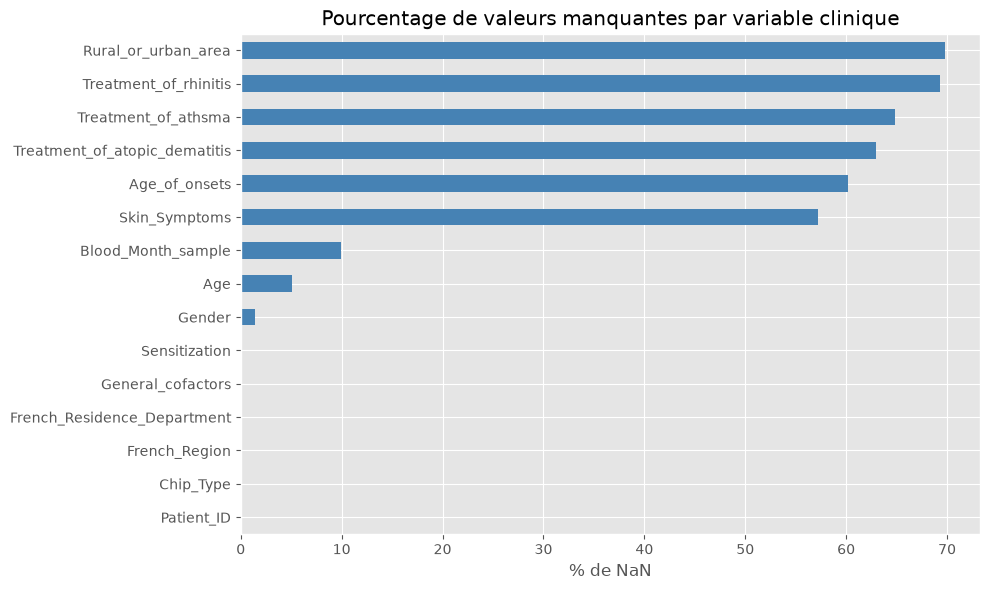

In [3]:
# --- AFFICHAGE 1 : Valeurs manquantes ---
missing_clinical = df[clinical_cols].isna().mean() * 100

plt.figure(figsize=(10, 6))
missing_clinical.sort_values().plot(kind='barh', color='steelblue')
plt.title('Pourcentage de valeurs manquantes par variable clinique')
plt.xlabel('% de NaN')
plt.tight_layout()
plt.show()

C:\Users\noe_s\AppData\Local\Temp\ipykernel_16604\2364743271.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Chip_Type', ax=ax1, palette='viridis')


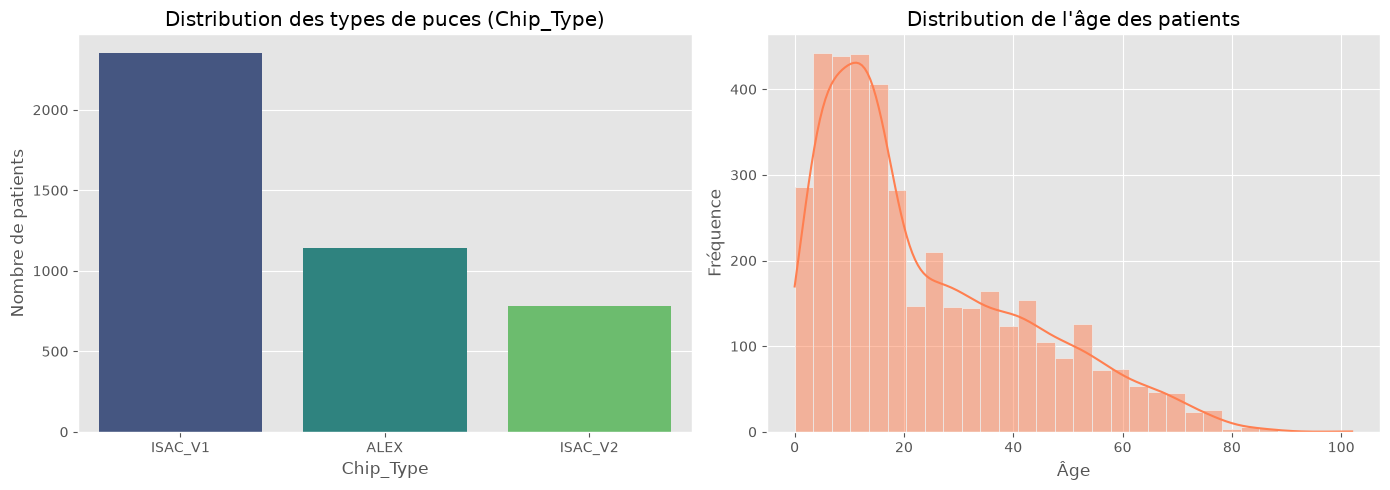

In [4]:
# --- AFFICHAGES 2 & 3 : Distributions (Puces et Âge) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='Chip_Type', ax=ax1, palette='viridis')
ax1.set_title('Distribution des types de puces (Chip_Type)')
ax1.set_ylabel('Nombre de patients')

sns.histplot(df['Age'], bins=30, kde=True, ax=ax2, color='coral')
ax2.set_title('Distribution de l\'âge des patients')
ax2.set_xlabel('Âge')
ax2.set_ylabel('Fréquence')
plt.tight_layout()
plt.show()

C:\Users\noe_s\AppData\Local\Temp\ipykernel_16604\3137374680.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['PCA1'] = bio_pca[:, 0]
C:\Users\noe_s\AppData\Local\Temp\ipykernel_16604\3137374680.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['PCA2'] = bio_pca[:, 1]


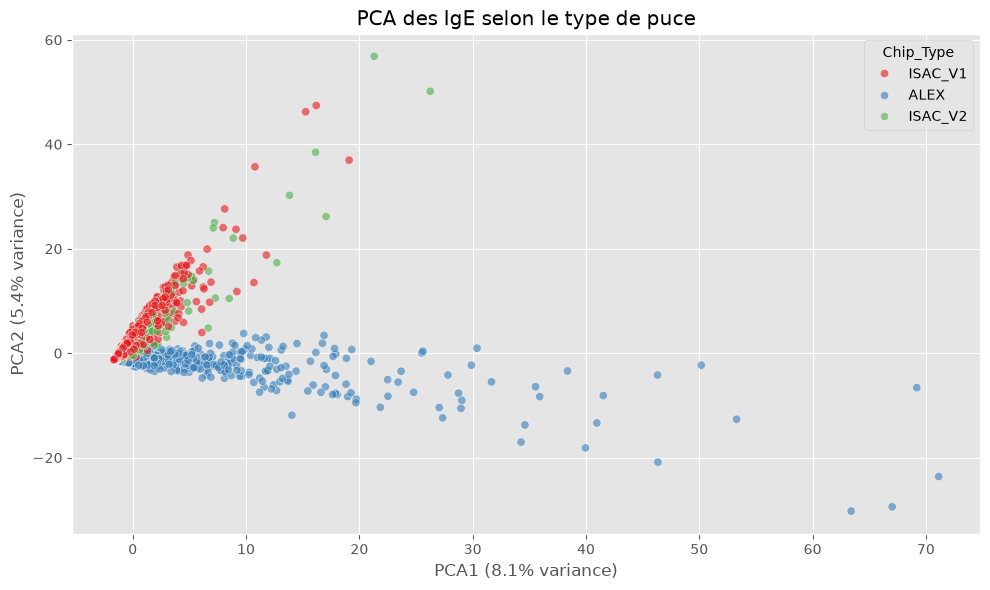

In [5]:
# --- AFFICHAGE 4 : PCA (Clustering visuel) ---
# On remplace temporairement les NaN biologiques par 0 pour faire tourner la PCA
bio_filled = df[biological_cols].fillna(0)

scaler = StandardScaler()
bio_scaled = scaler.fit_transform(bio_filled)

pca = PCA(n_components=2)
bio_pca = pca.fit_transform(bio_scaled)

df['PCA1'] = bio_pca[:, 0]
df['PCA2'] = bio_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='Chip_Type', alpha=0.6, palette='Set1')
plt.title('PCA des IgE selon le type de puce')
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.tight_layout()
plt.show()

In [6]:
# --- AFFICHAGE 5 : Groupes pour variables catégorielles ---

# 1. Évaluer les grandeurs pertinentes (Pourcentages) sur une variable catégorielle (ex: Chip_Type)
chip_pct = df['Chip_Type'].value_counts(normalize=True) * 100
print("--- Répartition Chip_Type (%) ---")
print(chip_pct)

# 2. Statistiques croisées : Moyenne, Variance, etc. d'une variable continue selon une catégorie
# Ex : L'âge selon le genre (0 = potentiellement F, 1 = M, à vérifier dans votre dictionnaire)
gender_age_stats = df.groupby('Gender')['Age'].agg(['count', 'mean', 'var', 'std', 'min', 'max'])
print("\n--- Statistiques d'Âge par Genre ---")
print(gender_age_stats)

--- Répartition Chip_Type (%) ---
Chip_Type
ISAC_V1    55.045657
ALEX       26.668228
ISAC_V2    18.286116
Name: proportion, dtype: float64

--- Statistiques d'Âge par Genre ---
        count       mean         var        std  min    max
Gender                                                     
0.0      2012  27.925447  348.289815  18.662524  0.0   87.0
1.0      2040  19.387745  320.988864  17.916162  0.0  102.0



--- Détection mathématique des valeurs aberrantes (IQR) ---
Variable Patient_ID : 0 valeurs aberrantes (hors bornes [nan, nan]).
Variable Chip_Type : 0 valeurs aberrantes (hors bornes [nan, nan]).
Variable Age : 31 valeurs aberrantes (hors bornes [-29.00, 75.00]).
Variable Gender : 0 valeurs aberrantes (hors bornes [-1.50, 2.50]).
Variable Blood_Month_sample : 0 valeurs aberrantes (hors bornes [-7.50, 20.50]).
Variable French_Residence_Department : 0 valeurs aberrantes (hors bornes [nan, nan]).
Variable French_Region : 0 valeurs aberrantes (hors bornes [nan, nan]).
Variable Rural_or_urban_area : 0 valeurs aberrantes (hors bornes [-1.50, 2.50]).
Variable Sensitization : 692 valeurs aberrantes (hors bornes [1.00, 1.00]).
Variable Treatment_of_rhinitis : 0 valeurs aberrantes (hors bornes [-3.00, 5.00]).
Variable Treatment_of_athsma : 7 valeurs aberrantes (hors bornes [-4.50, 7.50]).
Variable Age_of_onsets : 0 valeurs aberrantes (hors bornes [-6.00, 10.00]).
Variable Skin_Symptoms : 0 val

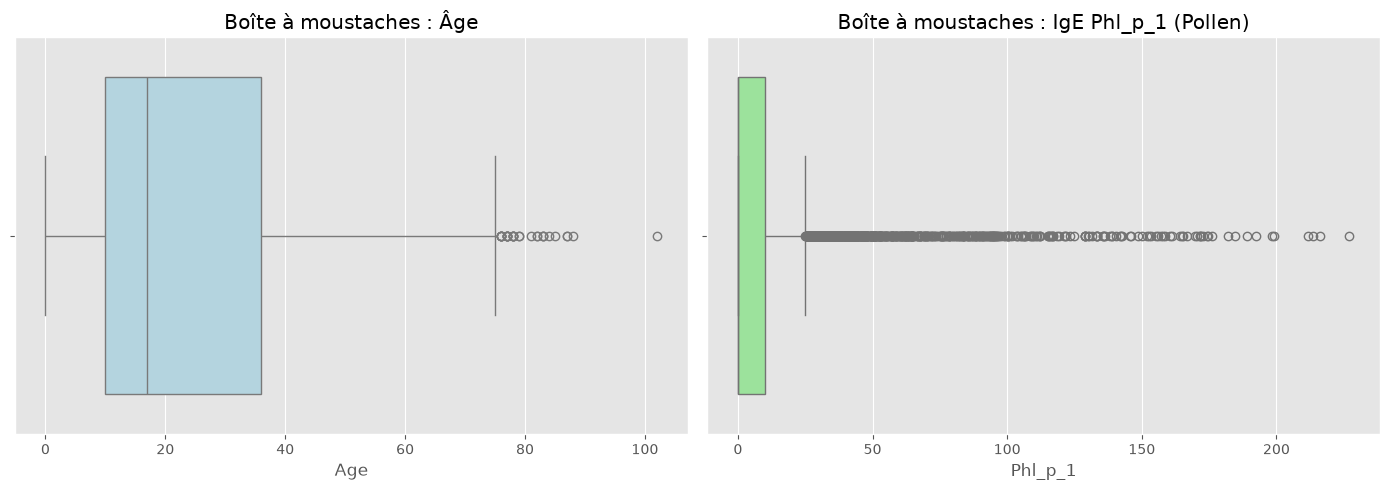

In [7]:
# --- Affichage 6 : Repérer les valeurs aberrantes (IQR & Boîtes à moustaches) ---

# On choisit d'analyser l'âge et un allergène spécifique (ex: Phl_p_1, un pollen)
cols_to_check = df.columns

print("\n--- Détection mathématique des valeurs aberrantes (IQR) ---")
for col in cols_to_check:
    # On s'assure que la colonne est bien numérique
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Définition des bornes
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filtrage des valeurs impossibles/aberrantes
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Variable {col} : {len(outliers)} valeurs aberrantes (hors bornes [{lower_bound:.2f}, {upper_bound:.2f}]).")

# Affichage graphique (Boîtes à moustaches)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=df['Age'], ax=ax1, color='lightblue')
ax1.set_title('Boîte à moustaches : Âge')

sns.boxplot(x=df['Phl_p_1'], ax=ax2, color='lightgreen')
ax2.set_title('Boîte à moustaches : IgE Phl_p_1 (Pollen)')

plt.tight_layout()
plt.show()